# SailGP Data Analyst Challenge — Auckland, 19 January 2025

All eight questions are answered below. The notebook runs top to bottom in a few minutes;
the reusable code lives in the small `sgp/` package next to it (`geo`, `course`, `wind`, `polar`, `race`),
with unit tests in `tests/`.

**What the data says, in one screen**

| # | Question | Result |
|---|---|---|
| 1 | Mean of a compass direction | Vector mean per time bin, with a quality flag. The plain mean is wrong by more than 5° in 5 % of the ten-second heading bins of this data set (95 of 1,855). |
| 2 | VMC from XML + lat/lon | Works from positions alone. But the XML is not where the marks were: the start line is ~200 m off at the gun, the leeward gate 75–110 m, and the course marks of the race 8 file 550–790 m, so marks are taken from the measured positions. Leg changes then match the logged leg counter to 0–1 s at the start line and to a median of 1–5 s at the gates and marks. |
| 3 | Calibration | Upwind, the fleet reports a true wind direction 3.5° further left on port than on starboard (3.1–4.1° in each fleet race): TWA reads ~1.8° too wide. A table per boat, point of sail and tack removes that flip on a held-out race. USA has a faulty bow wind sensor and a faulty starboard ride-height sensor. |
| 4 | Distance to leader | Progress along the course centre line; leader = most progress. |
| 5 | Minimum tacks / gybes | Dynamic programme in layline coordinates, inside the boundary: beats need 1–2 tacks depending on the gate marks chosen, runs 1 gybe, reaches 0. The median boat sailed that minimum on reaches and runs and one tack more on the beats. |
| 6 | Tacked variables | Signed channels mirrored, port/starboard pairs turned into windward/leeward. |
| 7 | Tack model | One thing dominates: staying on the foils. A tack that stays up loses nothing against target (median −7 m), one that comes down 62 m. Entry speed and peak turn rate are the two levers that predict it on teams the model has not seen (R² 0.78). |
| 8 | Race insights | Australia won race 5 and the final from the front; Denmark won 6 and 7. The first beat is the most expensive leg (37 % of all time lost to winners), and 70 % of the lost time is lower speed, not extra distance. |

## Setup

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sgp import course as crs
from sgp import data, geo, plots, race, wind
from sgp import polar as plr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 2)
plots.style()
C = plots.TEAM_COLOURS

logs = data.load_boat_logs()            # 1 Hz, UTC
marks = data.load_marks()               # measured mark positions + mark wind, 1 Hz
man = data.load_manoeuvres()            # one row per tack / gybe
straights = data.load_straight_lines()  # 10 s straight-line segments
polar = plr.Polar(data.load_polar())
courses_xml = data.load_courses()
RACES = sorted(courses_xml)

overview = logs.groupby("race").agg(boats=("BOAT", "nunique"), first=("DATETIME", "min"), last=("DATETIME", "max"), rows=("BOAT", "size"))
overview["start"] = [courses_xml[r].start_time for r in overview.index]
overview["started"] = logs[logs["TRK_LEG_NUM_unk"] >= 1].groupby("race")["BOAT"].nunique()
overview

,boats,first,last,rows,start,started
race,,,,,,
25011905,11,2025-01-19 02:56:08,2025-01-19 03:18:11,7092,2025-01-19 03:08:00,10
25011906,11,2025-01-19 03:18:29,2025-01-19 03:39:00,7394,2025-01-19 03:29:00,10
25011907,11,2025-01-19 03:48:00,2025-01-19 04:00:14,6766,2025-01-19 03:50:00,10
25011908,3,2025-01-19 04:12:00,2025-01-19 04:23:15,1985,2025-01-19 04:14:00,3


Four races: three fleet races (`25011905`–`07`) and the three-boat final (`25011908`).
Canada is in the logs but never starts. All timestamps are UTC; the XML start times carry a +13:00 offset and are converted.

## Question 1 — mean of a compass direction at a lower frequency

Averaging degrees breaks at north: the mean of 350° and 10° is 0°, not 180°. `geo.resample_direction` turns every sample into a unit
vector, sums the vectors per time bin and takes the direction of the sum. It also returns

* `r`, the length of the mean vector (1 = all samples agree, 0 = they cancel). A 10 s "mean heading" through a tack has a low `r` and should not be trusted, which `min_r` enforces;
* `std`, the circular standard deviation, and `n`, the number of samples, so gaps are visible instead of silently averaged over.

Bins are real time bins (`resample`), not a rolling window, so the output really is at the lower frequency. Passing `weights` (e.g. wind speed) gives a true vector average.

In [ ]:
demo = pd.Series([350.0, 355.0, 0.0, 5.0, 10.0], index=pd.date_range("2025-01-19 03:00", periods=5, freq="1s"))
print(f"plain mean: {demo.mean():.0f} deg   circular mean: {round(geo.resample_direction(demo, '10s')['mean'].iloc[0]) % 360} deg")

racing = logs[logs["TRK_LEG_NUM_unk"] >= 1].set_index("DATETIME")
rows = []
for (boat, rid), g in racing.groupby(["BOAT", "race"]):
    circ = geo.resample_direction(g["HEADING_deg"], "10s")
    naive = g["HEADING_deg"].resample("10s").mean()
    err = np.abs(geo.wrap180(naive - circ["mean"]))
    beat = g["TRK_LEG_NUM_unk"].resample("10s").median().isin([3, 5])
    rows.append({"bins": circ["mean"].notna().sum(), "wrong_by_5deg": (err > 5).sum(), "wrong_by_30deg": (err > 30).sum(), "on_a_beat": ((err > 5) & beat).sum()})
q1 = pd.DataFrame(rows).sum()
print(f"heading, all boats and races: {int(q1['wrong_by_5deg'])} of {int(q1['bins'])} ten-second bins ({q1['wrong_by_5deg'] / q1['bins']:.0%}) "
      f"have a plain mean more than 5 deg away from the circular mean;\n{int(q1['wrong_by_30deg'])} of those are more than 30 deg off, "
      f"{int(q1['on_a_beat'])} are on a beat (legs 3 and 5), where port tack is sailed close to north")

plain mean: 144 deg   circular mean: 0 deg


heading, all boats and races: 95 of 1855 ten-second bins (5%) have a plain mean more than 5 deg away from the circular mean;
84 of those are more than 30 deg off, 68 are on a beat (legs 3 and 5), where port tack is sailed close to north


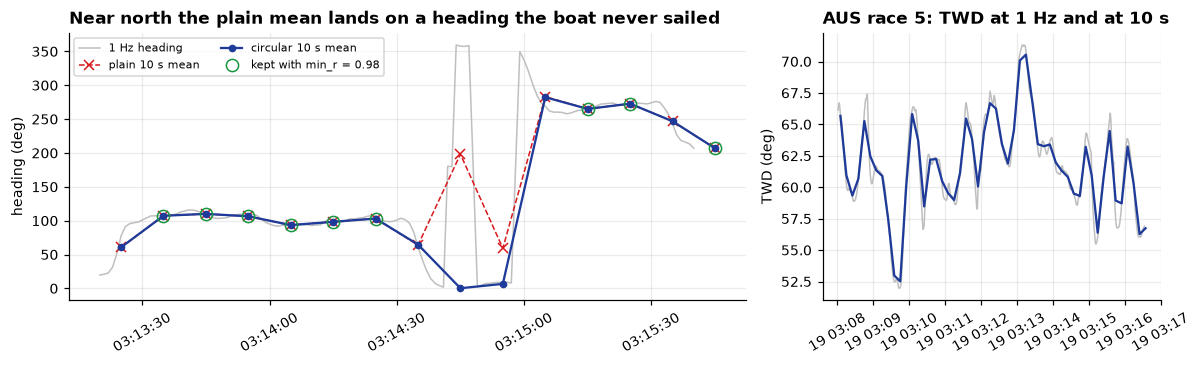

In [ ]:
g = racing[(racing["BOAT"] == "AUS") & (racing["race"] == 25011905)]
win = g.loc["2025-01-19 03:13:20":"2025-01-19 03:15:40"]
circ = geo.resample_direction(win["HEADING_deg"], "10s")
steady = geo.resample_direction(win["HEADING_deg"], "10s", min_r=0.98)
naive = win["HEADING_deg"].resample("10s").mean()
mid = circ.index + pd.Timedelta("5s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.plot(win.index, win["HEADING_deg"], color="0.75", lw=1, label="1 Hz heading")
ax.plot(mid, naive, "x--", color="#d7191c", lw=1, label="plain 10 s mean")
ax.plot(mid, circ["mean"], "o-", color="#1f3b99", ms=4, label="circular 10 s mean")
ax.plot(mid, steady["mean"], "o", color="#1a9641", ms=8, mfc="none", label="kept with min_r = 0.98")
ax.set_title("Near north the plain mean lands on a heading the boat never sailed")
ax.set_ylabel("heading (deg)")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
twd = geo.resample_direction(g["TWD_SGP_deg"], "10s")
ax.plot(g.index, g["TWD_SGP_deg"], color="0.75", lw=1)
ax.plot(twd.index + pd.Timedelta("5s"), twd["mean"], color="#1f3b99", lw=1.5)
ax.set_title("AUS race 5: TWD at 1 Hz and at 10 s")
ax.set_ylabel("TWD (deg)")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()

## Question 2 — VMC from a course XML and a lat/lon time series

VMC is the component of the boat's velocity towards the next mark. Three things are needed, all derived from time and position only:

1. **Velocity** — central differences of the positions in a local metric frame, lightly smoothed (3 s).
2. **Which mark is next** — `Course.detect_legs` walks the track through the waypoints of the XML. A line or gate counts when the track crosses it in the direction of the leg;
   a single mark counts when the track crosses the half-line that starts at the mark and points away from the inside of the turn. The start only counts after the start time.
3. **Where the mark is** — for a gate, the target is the closest point of the gate, so VMC stays meaningful right up to the line.

### First check the course file against reality

`Course_Marks` has the measured position of every mark at 1 Hz. Comparing it with the XML targets:

In [ ]:
rows = []
for rid in RACES:
    c = courses_xml[rid]
    at_gun = crs.measured_marks(marks, c.start_time - pd.Timedelta("10s"), c.start_time + pd.Timedelta("10s"))
    in_race = crs.measured_marks(marks, c.start_time + pd.Timedelta("2min"), c.start_time + pd.Timedelta("8min"))
    for wp in c.waypoints:
        for name, xy in zip(wp.mark_names, wp.xy):
            rows.append({"race": rid, "mark": name, "at the gun": np.linalg.norm(c.frame.to_xy(*at_gun[name]) - xy), "mid race": np.linalg.norm(c.frame.to_xy(*in_race[name]) - xy)})
offsets = pd.DataFrame(rows).drop_duplicates(["race", "mark"]).set_index(["mark", "race"]).unstack("race").round(0)
print("Distance between the XML target and the measured mark position (m)")
offsets

Distance between the XML target and the measured mark position (m)


at the gun                            mid race                           
race   25011905 25011906 25011907 25011908 25011905 25011906 25011907 25011908
mark                                                                          
FL1       205.0      6.0      5.0    143.0      3.0      5.0      5.0    144.0
FL2       195.0     97.0     97.0    175.0    167.0     97.0     98.0    175.0
LG1        72.0     88.0    109.0    550.0     79.0     91.0    110.0    550.0
LG2         7.0      6.0      7.0    753.0      6.0      6.0      6.0    756.0
M1          6.0      6.0      3.0    685.0      6.0      6.0      5.0    686.0
SL1       214.0    206.0    204.0    176.0      6.0      5.0      4.0      4.0
SL2       190.0    188.0    182.0    357.0     24.0      5.0      4.0      3.0
WG1       131.0     46.0      5.0    712.0      5.0      6.0      5.0    712.0
WG2       147.0     42.0      5.0    783.0      6.0      6.0      5.0    785.0

* The **start line** is ~200 m from its XML position at the gun and within 5–25 m of it a few minutes later: the XML is written about six minutes after the start (see `CreationTimeDate`), when the start buoys have already been moved.
* **LG1** is 75–110 m off while it is used as a gate (end of legs 2 and 4) and within 5 m for the final rounding: it is moved during the race. **FL2** is 100–170 m off mid-race in all three fleet races; in race 5 the windward gate is still 130–150 m off at the gun and in place a few minutes later.
* The **race 8** file is unusable: its turning marks (M1, both gates) are 550–790 m away from where they were and its legs 2–7 are 100–240 m long.

So the course used below is the XML *sequence* with each mark frozen where it was measured while the fleet went past it (`crs.as_raced_course`).
Everything still works from the XML alone (`Course.from_xml`), it is just less accurate.

In [ ]:
tracks = {rid: {b: g for b, g in logs[logs["race"] == rid].groupby("BOAT")} for rid in RACES}
courses = {rid: crs.as_raced_course(courses_xml[rid], marks, tracks[rid]) for rid in RACES}
metrics = {rid: race.race_tracks(logs, courses[rid]) for rid in RACES}   # logs + leg, progress, VMC

course = courses[25011905]
course.leg_table().round(0)

,from,to,bearing_deg,length_m
leg,,,,
1,SL1,M1,327.0,466.0
2,M1,LG1,244.0,1069.0
3,LG1,WG1,68.0,1253.0
4,WG1,LG1,248.0,1256.0
5,LG1,WG1,68.0,1255.0
6,WG1,LG1,242.0,1170.0
7,LG1,FL1,118.0,270.0


### Check the leg detection against the logged leg counter

The logs carry `TRK_LEG_NUM_unk`. It is not used anywhere in the calculation, which makes it an independent check.

In [ ]:
rows = []
for rid in RACES:
    for boat, m in metrics[rid].groupby("BOAT"):
        for k in range(1, courses[rid].n_legs + 1):
            mine, theirs = m.loc[m["leg"] >= k, "DATETIME"].min(), m.loc[m["TRK_LEG_NUM_unk"] >= k, "DATETIME"].min()
            if pd.notna(mine) and pd.notna(theirs):
                wp = courses[rid].waypoints[k - 1]
                rows.append({"waypoint": f"{k - 1} {wp.name}", "kind": "line / gate" if wp.is_gate else "single mark", "dt": (mine - theirs).total_seconds()})
check = pd.DataFrame(rows)
print(f"{len(check)} leg changes compared, {check['dt'].abs().le(10).mean():.0%} within 10 s")
check.groupby(["waypoint", "kind"])["dt"].agg(n="size", median_s="median", worst_s=lambda s: s.loc[s.abs().idxmax()]).T

227 leg changes compared, 97% within 10 s


waypoint,0 SL1,1 M1,2 LG1,3 WG1,4 LG1,5 WG1,6 LG1
kind,line / gate,single mark,line / gate,line / gate,line / gate,line / gate,single mark
n,33.0,33.0,33.0,32.0,32.0,32.0,32.0
median_s,0.0,-2.0,-3.0,-5.0,-2.0,-5.0,-1.0
worst_s,-1.0,-5.0,-19.0,-11.0,-12.0,-11.0,-8.0


Starts agree to the second. At gates and marks the geometric test fires a few seconds *before* the logged counter (median 1–5 s, 97 % within 10 s, worst case 19 s):
the counter seems to switch once the boat has cleared the mark, the geometry switches when it crosses the gate line. Neither is wrong; for VMC the earlier switch is the useful one.

### The VMC column

In [ ]:
aus = metrics[25011905].query("BOAT == 'AUS'")
aus.loc[aus["leg"] >= 1, ["DATETIME", "leg", "sog_kmh", "cog_deg", "brg_target_deg", "dist_target_m", "vmc_kmh"]].iloc[::45].head(8).set_index("DATETIME").round(1)

,leg,sog_kmh,cog_deg,brg_target_deg,dist_target_m,vmc_kmh
DATETIME,,,,,,
2025-01-19 03:08:01,1,78.1,340.4,322.4,472.7,74.3
2025-01-19 03:08:46,2,67.6,272.2,230.4,656.6,50.4
2025-01-19 03:09:32,3,57.3,96.4,62.6,1186.4,47.6
2025-01-19 03:10:18,3,50.4,14.0,45.7,702.7,42.9
2025-01-19 03:11:03,3,41.7,104.0,96.3,216.0,41.3
2025-01-19 03:11:49,4,54.4,213.6,264.8,1000.1,34.1
2025-01-19 03:12:34,4,75.9,265.1,244.6,373.5,71.1
2025-01-19 03:13:19,5,60.4,19.1,84.3,1058.0,25.4


speed from positions vs logged GPS SOG: median difference 0.5 km/h


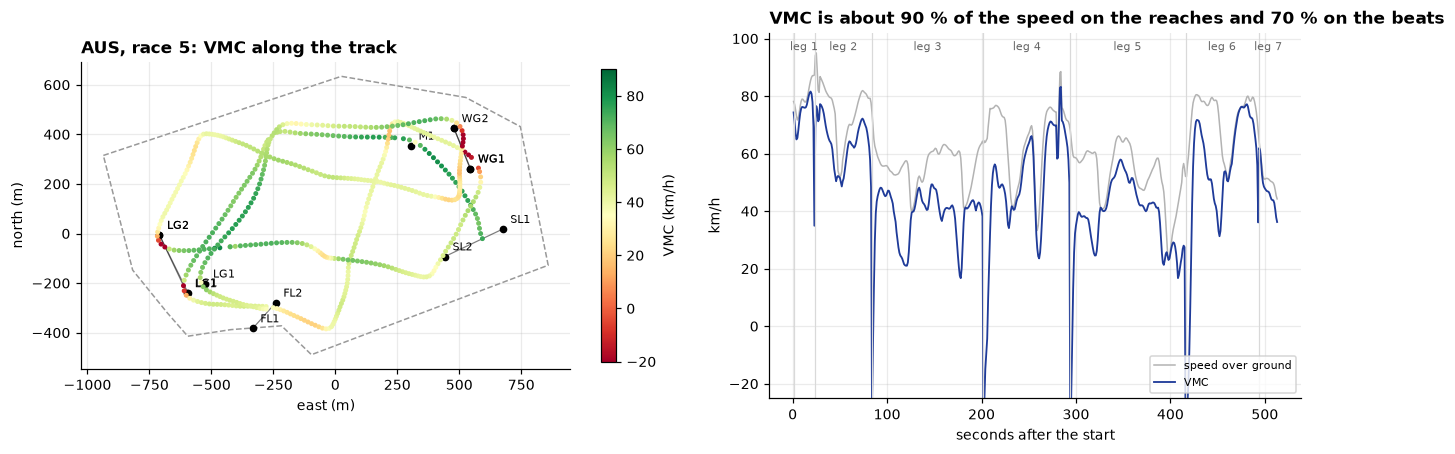

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = plots.plot_course(axes[0], course)
r = aus[aus["leg"].between(1, 7)]
sc = ax.scatter(r["x_m"], r["y_m"], c=r["vmc_kmh"], cmap="RdYlGn", vmin=-20, vmax=90, s=5, zorder=4)
plt.colorbar(sc, ax=ax, label="VMC (km/h)", shrink=0.8)
ax.set_title("AUS, race 5: VMC along the track")

ax = axes[1]
t = (r["DATETIME"] - course.start_time).dt.total_seconds()
ax.plot(t, r["sog_kmh"], color="0.7", lw=1, label="speed over ground")
ax.plot(t, r["vmc_kmh"], color="#1f3b99", lw=1.2, label="VMC")
for k in range(1, 8):
    seg = t[r["leg"] == k]
    ax.axvline(seg.iloc[0], color="0.85", lw=0.8)
    ax.text(seg.mean(), 96, f"leg {k}", ha="center", fontsize=7, color="0.4")
ax.set_ylim(-25, 102)
ax.set_xlabel("seconds after the start")
ax.set_ylabel("km/h")
ax.set_title("VMC is about 90 % of the speed on the reaches and 70 % on the beats")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()

err = (metrics[25011905]["sog_kmh"] - metrics[25011905]["GPS_SOG_km_h_1"]).abs()
print(f"speed from positions vs logged GPS SOG: median difference {err.median():.1f} km/h")

## Question 3 — calibration

There is no independent truth in the data set, so the check is built on two things that must hold whatever the wind does:

* **the wind does not know which tack a boat is on** — over a race, port and starboard tack must report the same wind;
* **boats within a few hundred metres see the same wind on average** — each boat is compared with the mean of the *other* boats at the same second.

Only steady sailing is used (racing, faster than 30 km/h, yaw rate below 3°/s).

### 3.1 What the wind channels are

In [ ]:
L = logs[logs["BOAT"] != "CAN"].copy()
closure = pd.Series(geo.wrap180(L["TWD_SGP_deg"] - L["HEADING_deg"] - L["TWA_SGP_deg"]), index=L.index)
awa_from_true, _ = wind.apparent_from_true(L["TWA_SGP_deg"], L["TWS_SGP_km_h_1"], L["BOAT_SPEED_km_h_1"])
steady = wind.steady_sailing(L)
awa_closure = pd.Series(geo.wrap180(awa_from_true - L["AWA_SGP_deg"]), index=L.index)
print(f"TWD - HEADING - TWA      : median {closure[steady].median():+.2f} deg, IQR {closure[steady].quantile(.75) - closure[steady].quantile(.25):.1f} deg  -> on average TWD = heading + TWA; the logged TWD is the smoother of the two")
print(f"AWA rebuilt from TWA, TWS, boat speed vs logged AWA: sd {awa_closure[steady].std():.1f} deg  -> the wind triangle uses boat speed along the heading")

s = straights[(straights["TRK_LEG_NUM_unk"] >= 1) & straights["MODE"].notna()]
sensors = pd.DataFrame({
    "TWS bow / masthead": (s["TWS_BOW_SGP_km_h_1"] / s["TWS_MHU_SGP_km_h_1"]).groupby(s["BOAT"]).median(),
    "TWD bow - masthead (deg)": pd.Series(geo.wrap180(s["TWD_BOW_SGP_deg"] - s["TWD_MHU_SGP_deg"]), index=s.index).groupby(s["BOAT"]).median(),
    "TWD SGP - masthead (deg)": pd.Series(geo.wrap180(s["TWD_SGP_deg"] - s["TWD_MHU_SGP_deg"]), index=s.index).groupby(s["BOAT"]).median(),
})
rh = L[steady & (L["BOAT_SPEED_km_h_1"] > 50)].groupby("BOAT")[["LENGTH_RH_P_mm", "LENGTH_RH_S_mm", "LENGTH_RH_BOW_mm"]].median()
pd.concat([sensors, rh], axis=1).round(2).T

TWD - HEADING - TWA      : median -0.08 deg, IQR 7.3 deg  -> on average TWD = heading + TWA; the logged TWD is the smoother of the two
AWA rebuilt from TWA, TWS, boat speed vs logged AWA: sd 1.3 deg  -> the wind triangle uses boat speed along the heading


BOAT,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
TWS bow / masthead,0.98,0.97,0.97,0.99,0.97,0.95,0.94,1.00,0.93,0.70
TWD bow - masthead (deg),0.95,0.05,0.92,0.95,-0.35,0.34,1.83,-0.32,0.55,18.66
TWD SGP - masthead (deg),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
LENGTH_RH_P_mm,995.05,1012.90,966.20,975.65,995.72,917.67,1061.82,946.15,987.58,874.79
LENGTH_RH_S_mm,994.24,947.99,941.36,974.66,972.70,908.28,1080.16,960.64,986.50,-801.86
LENGTH_RH_BOW_mm,983.49,1032.60,885.06,964.87,946.18,871.90,980.92,916.38,933.78,831.68


* The `_SGP` wind **is** the masthead unit (difference exactly 0 on every boat).
* The bow sensor reads 0–7 % less wind than the masthead, as expected lower down. **USA's bow sensor is faulty** (30 % low in the median, direction scattered over tens of degrees) — harmless only because the masthead is the source.
* **USA's starboard ride-height sensor reads about −800 mm all through the racing.** Any metric that averages port and starboard ride height is wrong for USA; the code below uses the median of the three sensors.

### 3.2 The fleet-wide signature: TWD flips with the tack upwind

In [ ]:
S = L[steady].copy()
S["TWD_inst"] = wind.instantaneous_twd(S)          # heading + TWA, unfiltered
fleet = S[S["race"] != 25011908]                   # the final has 3 boats: too few for a fleet reference
flip = wind.tack_flip(fleet, "TWD_inst").drop("reach", level="sail")
flip.round(2)

flip_deg  tws_ratio  n_port  n_stbd
race     sail                                         
25011905 downwind      0.33       1.07     728     768
         upwind       -4.08       1.02    1054     916
25011906 downwind     -0.11       1.02     795     733
         upwind       -3.12       1.02    1051    1039
25011907 downwind     -0.96       1.07     721     750
         upwind       -3.14       1.00    1057     909

Upwind, the fleet reports a TWD **3–4° further left on port tack than on starboard, in all three races**; downwind the flip stays under 1°.
Since `TWD = heading + TWA`, this means |TWA| reads about 1.8° too wide upwind on both tacks. That is what upwash at the masthead sensor would produce (an apparent wind speed that reads a little low would do the same); the data cannot tell the two apart.

It is **not leeway**. The logged wind triangle ignores leeway, so that was the first suspect, but putting the logged leeway into the triangle with its physical sign makes the flip *bigger*:

In [ ]:
awa, aws = wind.apparent_from_true(fleet["TWA_SGP_deg"], fleet["TWS_SGP_km_h_1"], fleet["BOAT_SPEED_km_h_1"])
apparent = aws.to_numpy()[:, None] * geo.unit_from_bearing(fleet["HEADING_deg"] + awa)      # 'from' vector, earth frame
rows = {}
for label, direction, speed in [("as logged: boat speed along heading", fleet["HEADING_deg"], fleet["BOAT_SPEED_km_h_1"]),
                                ("with leeway: course through water", fleet["HEADING_deg"] - fleet["LEEWAY_deg"], fleet["BOAT_SPEED_km_h_1"]),
                                ("over ground: GPS COG and SOG", fleet["GPS_COG_deg"], fleet["GPS_SOG_km_h_1"])]:
    true = apparent - speed.to_numpy()[:, None] * geo.unit_from_bearing(direction)
    f = wind.tack_flip(fleet.assign(_twd=geo.bearing_of(true), _tws=np.linalg.norm(true, axis=1), _all=0), "_twd", "_tws", by=("_all",)).droplevel(0)
    rows[label] = {"upwind flip (deg)": f.loc["upwind", "flip_deg"], "downwind flip (deg)": f.loc["downwind", "flip_deg"]}
pd.DataFrame(rows).T.round(2)

,upwind flip (deg),downwind flip (deg)
as logged: boat speed along heading,-3.51,-0.20
with leeway: course through water,-5.98,0.09
over ground: GPS COG and SOG,-6.04,0.01


### 3.3 Boat by boat, against the rest of the fleet

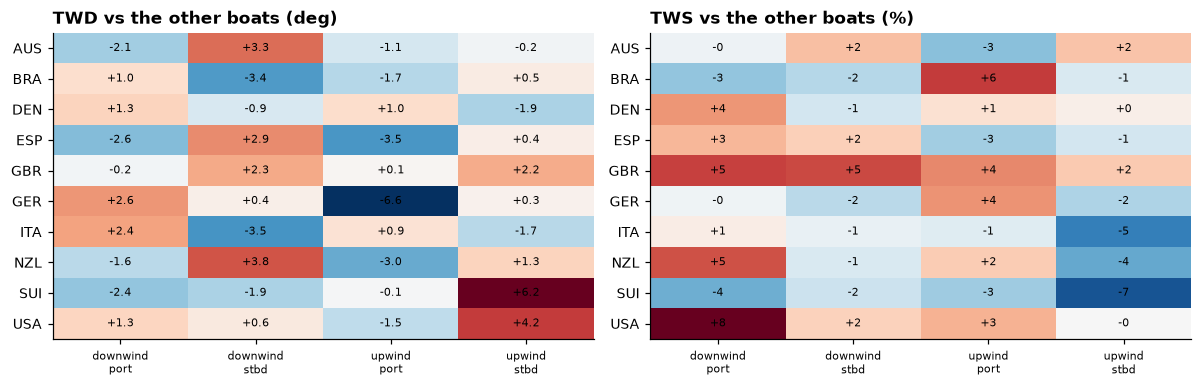

In [ ]:
res = wind.calibration_residuals(fleet, "TWD_inst", "TWS_SGP_km_h_1")
res = res[res["sail"] != "reach"]
cells = res.groupby(["BOAT", "sail", "tack"]).agg(d=("d_twd", "mean"), r=("r_tws", "mean"))
d_twd = cells["d"].unstack(["sail", "tack"])
r_tws = (100 * (cells["r"] - 1)).unstack(["sail", "tack"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, tab, title, lim, unit in [(axes[0], d_twd, "TWD vs the other boats (deg)", 6, "{:+.1f}"), (axes[1], r_tws, "TWS vs the other boats (%)", 8, "{:+.0f}")]:
    im = ax.imshow(tab.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), [f"{a}\n{b}" for a, b in tab.columns], fontsize=7)
    ax.set_yticks(range(tab.shape[0]), tab.index)
    for (i, j), v in np.ndenumerate(tab.to_numpy()):
        ax.text(j, i, unit.format(v), ha="center", va="center", fontsize=7)
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()

Read across a row: the same sign in all four cells is a constant angle error (sensor alignment, compass); opposite signs on port and starboard are a TWA magnitude error;
a TWS column that is off is an apparent wind speed error. SUI on starboard upwind (+6°, −7 % TWS), GER on port upwind (−7°) and USA on starboard upwind (+4°) are the large ones in direction; GBR reads 2–6 % more wind than the others in all four cells.

### 3.4 Proposed calibration table and post-calibrated wind

`wind.fit_calibration` turns this into a table per boat, point of sail and tack: `dtwa_deg` is subtracted from the logged TWA (and so from TWD), `tws_factor` divides the logged TWS.
The TWA correction is the fleet-wide half-flip plus the boat's own offset to the fleet; the boat part is shrunk towards zero where a cell has few samples.
To see whether it is a calibration and not a fit to noise, it is **fitted on races 5 and 6 and applied to race 7**.

In [ ]:
train, test = fleet[fleet["race"] != 25011907], fleet[fleet["race"] == 25011907]
table_train = wind.fit_calibration(train)


def spread(df, twd, tws):
    r = wind.calibration_residuals(df, twd, tws)
    cell = r[r["sail"] != "reach"].groupby(["BOAT", "sail", "tack"]).agg(d=("d_twd", "mean"), s=("r_tws", "mean"), n=("d_twd", "size")).query("n >= 30")
    f = wind.tack_flip(df, twd, tws)["flip_deg"].groupby("sail").mean()
    return {"upwind flip (deg)": f["upwind"], "downwind flip (deg)": f["downwind"], "boat-cell TWD rms (deg)": np.sqrt((cell["d"] ** 2).mean()), "boat-cell TWS rms (%)": 100 * np.sqrt(((cell["s"] - 1) ** 2).mean())}


rows = {}
for label, df in [("races 5+6 (fitted)", train), ("race 7 (held out)", test)]:
    cal = wind.apply_calibration(df, table_train)
    rows[(label, "logged")] = spread(df, "TWD_inst", "TWS_SGP_km_h_1")
    rows[(label, "calibrated")] = spread(cal, "TWD_cal_deg", "TWS_cal_km_h_1")
pd.DataFrame(rows).T.round(2)

upwind flip (deg)  downwind flip (deg)  boat-cell TWD rms (deg)  boat-cell TWS rms (%)
races 5+6 (fitted) logged                  -3.60                 0.11                     2.49                   3.61
                   calibrated              -0.27                 0.39                     0.57                   1.15
race 7 (held out)  logged                  -3.14                -0.96                     3.21                   4.10
                   calibrated               0.22                -0.81                     2.26                   3.58

On the held-out race the upwind flip goes from −3.1° to +0.2° and the spread between boats drops by 30 % in direction (3.2° to 2.3° rms) and 13 % in speed (4.1 % to 3.6 %).
On the races it was fitted on, the same spread drops to 0.6° and 1.2 %. So the fleet-wide part transfers fully and the boat-specific part only partly, which is what two ten-minute races can support. More days would firm it up.

The table fitted on all three fleet races, and the post-calibrated channels:

In [ ]:
calibration = wind.fit_calibration(fleet)
logs_cal = wind.apply_calibration(L, calibration)   # adds TWA_cal_deg, TWD_cal_deg, TWS_cal_km_h_1 to every row
show = calibration.drop("reach", level="sail")
pd.concat({"TWA correction to subtract (deg)": show["dtwa_deg"].unstack(["sail", "tack"]), "TWS divisor": show["tws_factor"].unstack(["sail", "tack"])}, axis=1).round(2)

TWA correction to subtract (deg)                    TWS divisor                   
sail                         downwind       upwind          downwind       upwind      
tack                             port  stbd   port  stbd        port  stbd   port  stbd
BOAT                                                                                   
AUS                             -1.48  2.37  -1.10  1.66        1.00  1.02   0.97  1.02
BRA                              0.73 -2.49  -2.00  0.80        0.97  0.98   1.04  0.99
DEN                              0.87 -0.67   0.35 -0.99        1.03  0.99   1.01  1.00
ESP                             -2.04  2.32  -3.31  0.79        1.02  1.01   0.98  0.99
GBR                             -0.13  1.85  -0.32  2.27        1.04  1.04   1.03  1.02
GER                              1.94  0.37  -6.01  0.63        1.00  0.98   1.03  0.98
ITA                              1.73 -2.49   0.00 -0.72        1.00  1.00   0.99  0.95
NZL                             -1.33  3.05  -2.87  1.36        1.04  0.99   1.02  0.97
SUI                             -1.74 -1.48  -0.45  5.43        0.97  0.99   0.98  0.94
USA                              0.85  0.51  -1.76  3.82        1.06  1.01   1.02  1.00

In [ ]:
mark_wind = marks[(marks["DATETIME"] >= "2025-01-19 03:08") & (marks["DATETIME"] <= "2025-01-19 04:00")].groupby("MARK").agg(
    TWD=("TWD_deg", wind.circular_mean_deg), TWD_sd=("TWD_deg", "std"), TWS=("TWS_km_h_1", "mean"))
boats_now = logs_cal[steady.reindex(logs_cal.index, fill_value=False) & (logs_cal["race"] != 25011908)]
print(f"boats, calibrated: TWD {wind.circular_mean_deg(boats_now['TWD_cal_deg']):.1f} deg, TWS {boats_now['TWS_cal_km_h_1'].mean():.1f} km/h")
mark_wind.round(1).T

boats, calibrated: TWD 62.1 deg, TWS 37.9 km/h


MARK,FL1,FL2,LG1,LG2,M1,SL1,SL2,WG1,WG2
TWD,67.1,72.2,66.6,63.7,63.4,64.6,70.0,63.5,61.5
TWD_sd,5.0,6.9,5.9,5.0,4.7,10.4,12.0,9.6,5.4
TWS,31.1,32.1,33.9,36.2,31.8,31.4,32.3,25.0,30.2


**Limits.** A fleet-relative method cannot see an error that every boat shares on both tacks. The mark anemometers cannot settle that: they sit low above the water
(5–35 % less wind than the boats), scatter 5–12° and disagree with each other by up to 11°. The boats' mean direction (62°) lies at the low end of the range of the marks (61–72°): no sign of a large common offset, but a few degrees cannot be excluded.
One thing is left unexplained: downwind, port gybe shows 2–7 % more wind than starboard gybe in every race. That can be real (each gybe is sailed on its own side of the course), so it is reported, not corrected.
The proper next step is a dedicated calibration run: straight legs on reciprocal headings in steady wind, away from other boats.

## Question 4 — distance to leader

Each position is turned into **progress**: metres sailed along the course centre line (gate centre to gate centre). Completed legs count in full; on the current leg the boat is
projected onto the leg axis, measured to the gate *line*, so progress is continuous through a gate wherever the boat crosses it. The leader is the boat with the most progress
and distance to leader is the difference. It is a ladder position along the course, not a prediction of time: on a beat it does not know about laylines or shifts.

In [ ]:
dtl, progress, legs = crs.distance_to_leader(tracks[25011905], course)
dtl_race = dtl.loc[course.start_time:].dropna(how="all").drop(columns="CAN", errors="ignore")
dtl_race.iloc[::60].round(0)

,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
2025-01-19 03:08:01,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-01-19 03:09:01,0.0,222.0,128.0,125.0,85.0,211.0,145.0,180.0,258.0,266.0
2025-01-19 03:10:01,0.0,419.0,224.0,424.0,161.0,393.0,371.0,181.0,404.0,434.0
2025-01-19 03:11:01,0.0,402.0,282.0,479.0,72.0,331.0,474.0,252.0,437.0,541.0
2025-01-19 03:12:01,53.0,495.0,492.0,543.0,0.0,495.0,534.0,480.0,569.0,615.0
2025-01-19 03:13:01,144.0,797.0,359.0,614.0,0.0,386.0,533.0,591.0,921.0,910.0
2025-01-19 03:14:01,12.0,549.0,532.0,452.0,0.0,502.0,459.0,481.0,725.0,691.0
2025-01-19 03:15:01,0.0,408.0,455.0,278.0,26.0,342.0,278.0,273.0,618.0,608.0
2025-01-19 03:16:01,0.0,861.0,957.0,551.0,140.0,731.0,468.0,569.0,1003.0,994.0
2025-01-19 03:17:01,NaN,308.0,371.0,112.0,NaN,230.0,0.0,106.0,666.0,580.0


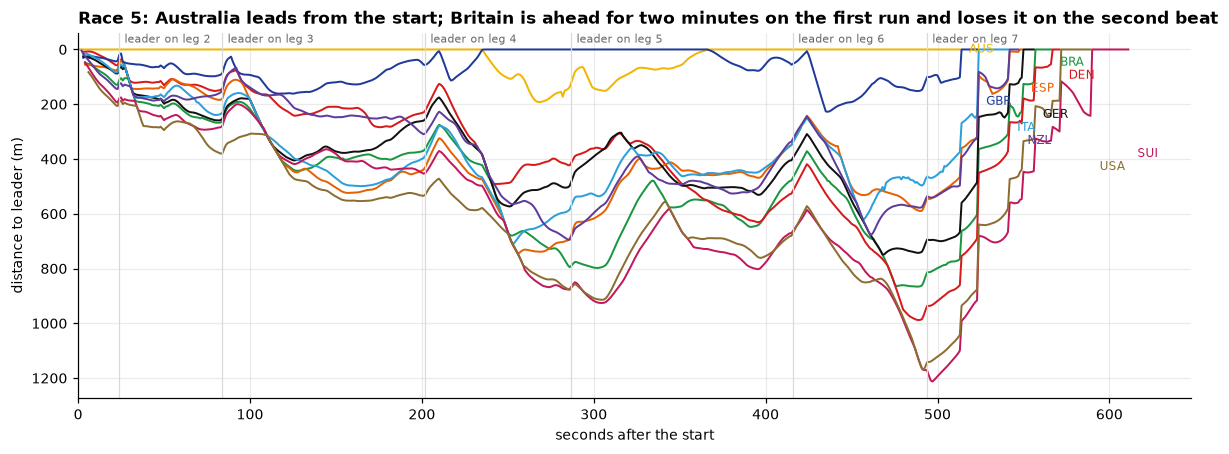

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.2))
t = (dtl_race.index - course.start_time).total_seconds()
for boat in dtl_race:
    ax.plot(t, dtl_race[boat], color=C[boat], lw=1.3)
leader_leg = legs.loc[dtl_race.index].max(axis=1)
for k in range(2, 8):
    ax.axvline(t[(leader_leg >= k).to_numpy().argmax()], color="0.85", lw=0.8)
    ax.text(t[(leader_leg >= k).to_numpy().argmax()] + 3, -25, f"leader on leg {k}", fontsize=7, color="0.4")
ax.invert_yaxis()
plots.label_lines(ax, dtl_race.set_axis(t))
ax.set_xlim(0, t.max() * 1.06)
ax.set_xlabel("seconds after the start")
ax.set_ylabel("distance to leader (m)")
ax.set_title("Race 5: Australia leads from the start; Britain is ahead for two minutes on the first run and loses it on the second beat")
plt.tight_layout()

In [ ]:
at_marks = {}
for k in range(2, 9):
    reached = leader_leg >= k
    if reached.any():
        at_marks[f"leader ends leg {k - 1}"] = dtl_race.loc[reached.idxmax()]
final_order = race.leg_times(metrics[25011905], course)[8].sort_values().index
pd.DataFrame(at_marks).reindex(final_order).round(0)

,leader ends leg 1,leader ends leg 2,leader ends leg 3,leader ends leg 4,leader ends leg 5,leader ends leg 6,leader ends leg 7
BOAT,,,,,,,
AUS,0.0,0.0,0.0,119.0,0.0,0.0,NaN
GBR,19.0,85.0,57.0,0.0,52.0,100.0,NaN
ITA,61.0,229.0,388.0,569.0,337.0,463.0,0.0
NZL,127.0,148.0,307.0,683.0,325.0,535.0,106.0
ESP,49.0,179.0,430.0,676.0,338.0,545.0,112.0
GER,68.0,252.0,254.0,482.0,395.0,694.0,230.0
BRA,110.0,261.0,363.0,790.0,467.0,813.0,308.0
DEN,40.0,142.0,223.0,413.0,515.0,936.0,371.0
USA,190.0,379.0,530.0,870.0,669.0,1141.0,580.0


The same picture as an interactive Bokeh chart (hover for boat and distance) is written to `figures/dtl_race5.html`.

In [ ]:
from pathlib import Path

from bokeh.models import HoverTool
from bokeh.plotting import figure, output_file, save

Path("figures").mkdir(exist_ok=True)
output_file("figures/dtl_race5.html", title="Distance to leader, race 5")
p = figure(width=1000, height=450, title="Distance to leader, race 5 (m)", x_axis_label="seconds after the start", y_axis_label="distance to leader (m)", y_range=(float(np.nanmax(dtl_race.to_numpy())) * 1.05, -20))
for boat in dtl_race:
    r = p.line(t, dtl_race[boat].to_numpy(), color=C[boat], line_width=2, legend_label=boat, name=boat)
p.add_tools(HoverTool(tooltips=[("boat", "$name"), ("t", "@x{0} s"), ("DTL", "@y{0} m")]))
p.legend.click_policy = "hide"
p.legend.location = "bottom_left"
_ = save(p)

## Question 5 — minimum number of tacks or gybes per leg and per gate mark

Inputs: the course, a wind direction and speed, and the polar.

1. The polar gives the best-VMG angles for the wind speed. A leg whose direct course lies at or between those angles is a fetch: **0** manoeuvres.
2. Otherwise the boat sails only its two best-VMG headings. Every such route is a staircase in the coordinate system spanned by those two headings; each corner is one manoeuvre.
3. A dynamic programme finds the staircase with the fewest corners that stays inside the course boundary (here with a 20 m margin). That works for a boundary of any shape and
   also tells you *where* the manoeuvres have to be.

Every gate mark is a separate target, and a separate starting point for the next leg.

In [ ]:
race_wind = {}
for rid in RACES:
    w = logs_cal[(logs_cal["race"] == rid) & steady.reindex(logs_cal.index, fill_value=False)]
    race_wind[rid] = (wind.circular_mean_deg(w["TWD_cal_deg"]), w["TWS_cal_km_h_1"].mean())
twd5, tws5 = race_wind[25011905]
targets = polar.targets(tws5)
print(f"race 5 wind: {twd5:.0f} deg, {tws5:.0f} km/h -> best VMG at TWA {targets['up_twa']:.0f} upwind ({targets['up_bsp']:.0f} km/h) and {targets['down_twa']:.0f} downwind ({targets['down_bsp']:.0f} km/h)")

mm = plr.course_min_manoeuvres(course, twd5, tws5, polar, margin=20)
mm.drop(columns="path").set_index(["leg", "mode", "from", "to"])["manoeuvres"].unstack("to").map(lambda v: "" if pd.isna(v) else int(v))

race 5 wind: 61 deg, 39 km/h -> best VMG at TWA 44 upwind (60 km/h) and 152 downwind (76 km/h)


to               FL1 FL2 LG1 LG2 M1 WG1 WG2
leg mode  from                             
1   fetch mid SL                  0        
2   run   M1               1   1           
3   beat  LG1                         2   2
          LG2                         1   1
4   run   WG1              1   1           
          WG2              1   1           
5   beat  LG1                         2   2
          LG2                         1   1
6   run   WG1              1               
          WG2              1               
7   fetch LG1      0   0

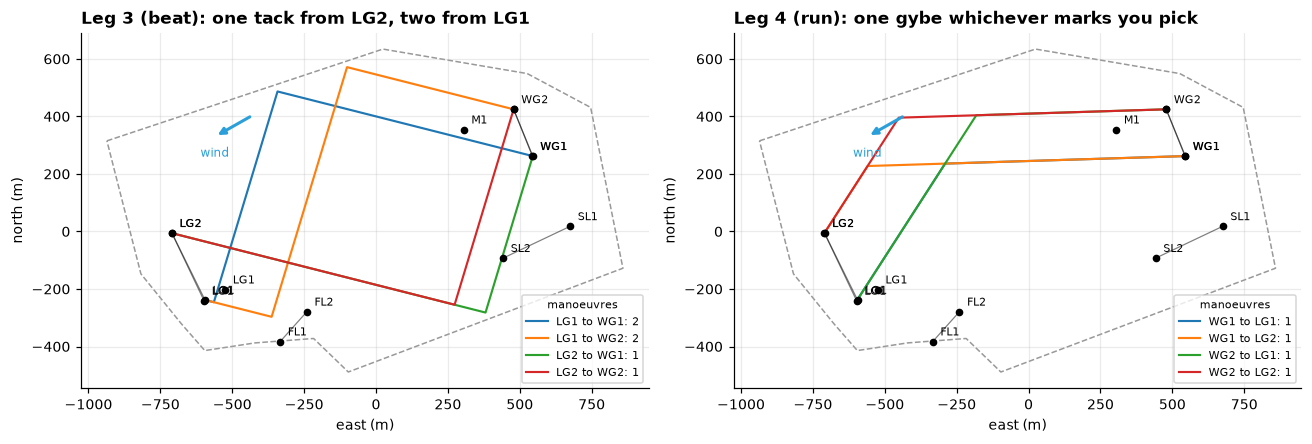

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, leg, title in [(axes[0], 3, "Leg 3 (beat): one tack from LG2, two from LG1"), (axes[1], 4, "Leg 4 (run): one gybe whichever marks you pick")]:
    plots.plot_course(ax, course)
    for i, (_, r) in enumerate(mm[mm["leg"] == leg].iterrows()):
        ax.plot(r["path"][:, 0], r["path"][:, 1], lw=1.4, color=plt.cm.tab10(i), label=f"{r['from']} to {r['to']}: {r['manoeuvres']}")
    ax.annotate("", xy=(-560, 330), xytext=(-560 + 150 * np.sin(np.radians(twd5)), 330 + 150 * np.cos(np.radians(twd5))), arrowprops=dict(arrowstyle="-|>", color="#2b9fd9", lw=2))
    ax.text(-560, 260, "wind", color="#2b9fd9", fontsize=8, ha="center")
    ax.set_title(title)
    ax.legend(fontsize=7, loc="lower right", title="manoeuvres", title_fontsize=7)
plt.tight_layout()

In [ ]:
rows = []
for rid in RACES:
    twd_r, tws_r = race_wind[rid]
    need = plr.course_min_manoeuvres(courses[rid], twd_r, tws_r, polar, margin=20).groupby("leg")["manoeuvres"].min()
    sailed = man[(man["race"] == rid) & man["leg"].between(1, 7)].groupby(["BOAT", "leg"]).size().unstack("leg").reindex(columns=range(1, 8)).fillna(0)
    finishers = race.leg_times(metrics[rid], courses[rid])[8].dropna().index
    sailed = sailed.reindex(finishers).fillna(0)
    for leg in range(1, 8):
        rows.append({"race": rid, "leg": leg, "minimum": need[leg], "fleet min": sailed[leg].min(), "fleet median": sailed[leg].median(), "fleet max": sailed[leg].max()})
compare = pd.DataFrame(rows).set_index(["race", "leg"])
print("Minimum from the model vs manoeuvres actually sailed (manoeuvre summary, finishers only)")
compare.unstack("race").swaplevel(axis=1).sort_index(axis=1).astype(int)

Minimum from the model vs manoeuvres actually sailed (manoeuvre summary, finishers only)


race  25011905                                 25011906                                 25011907                                 25011908                               
     fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum
leg                                                                                                                                                                     
1            0            0         0       0         1            0         0       0         1            0         0       0         1            1         0       0
2            3            1         1       1         2            1         0       1         2            1         1       1         1            1         1       1
3            2            2         1       1         2            2         1       1         3            2         1       1         2            2         2       2
4            2            1         1       1         2            1         1       1         3            1         1       1         2            2         1       1
5            2            2         1       1         2            2         0       1         2            2         1       1         2            1         1       1
6            1            1         1       1         2            1         1       1         2            1         0       1         2            2         1       1
7            1            0         0       0         0            0         0       0         1            0         0       0         0            0         0       0

The boat with the fewest manoeuvres sails exactly the model's minimum on 25 of the 28 legs. The median boat sails the minimum on the reaches and runs and one tack more on the beats of the fleet races.
Where a boat is *below* the minimum (three legs) it sailed outside the assumptions: wider than best VMG to fetch a mark, or closer to the boundary than the 20 m margin.
Not modelled: the distance lost in the manoeuvre itself, other boats, and wind shifts during the leg.

## Question 6 — "tacked" variables

`wind.add_tacked` makes every tack-dependent channel read the same on both tacks:

* **signed channels** (TWA, AWA, leeway, heel, yaw rate, rudder, wing rotation, twist, cambers) are mirrored on port tack, so a value always means the same thing relative to the wind (`*_tk`);
* **port / starboard pairs** (ride height, daggerboard rake and cant) become **windward / leeward** (`*_WW_*`, `*_LW_*`).

The tack comes from the sign of the TWA (negative = wind over the port side), held over 3 s so it does not flicker in the middle of a manoeuvre.
Which channels flip was checked in the data (yaw rate and rudder sit near zero in steady sailing; they are mirrored because they are signed by side):

In [ ]:
tk = wind.add_tacked(L)
tk["sail"] = wind.point_of_sail(tk["TWA_SGP_deg"])
up = tk[steady & (tk["sail"] == "upwind")]
raw = up.groupby("tack")[wind.SIGNED_CHANNELS].median().T
raw["tacked port"], raw["tacked stbd"] = up[up["tack"] == "port"][[c + "_tk" for c in wind.SIGNED_CHANNELS]].median().to_numpy(), up[up["tack"] == "stbd"][[c + "_tk" for c in wind.SIGNED_CHANNELS]].median().to_numpy()
raw.columns = ["raw port", "raw stbd", "tacked port", "tacked stbd"]
raw.round(1)

,raw port,raw stbd,tacked port,tacked stbd
TWA_SGP_deg,-47.9,46.8,47.9,46.8
AWA_SGP_deg,-20.4,19.9,20.4,19.9
LEEWAY_deg,-1.5,1.7,1.5,1.7
HEEL_deg,1.0,-1.3,-1.0,-1.3
RATE_YAW_deg_s_1,-0.2,0.1,0.2,0.1
ANGLE_RUDDER_deg,-0.6,0.1,0.6,0.1
ANGLE_WING_ROT_deg,-14.4,14.3,14.4,14.3
ANGLE_WING_TWIST_deg,-29.2,28.2,29.2,28.2
ANGLE_CA1_deg,16.6,-16.7,-16.6,-16.7
ANGLE_CA2_deg,10.0,-10.4,-10.0,-10.4


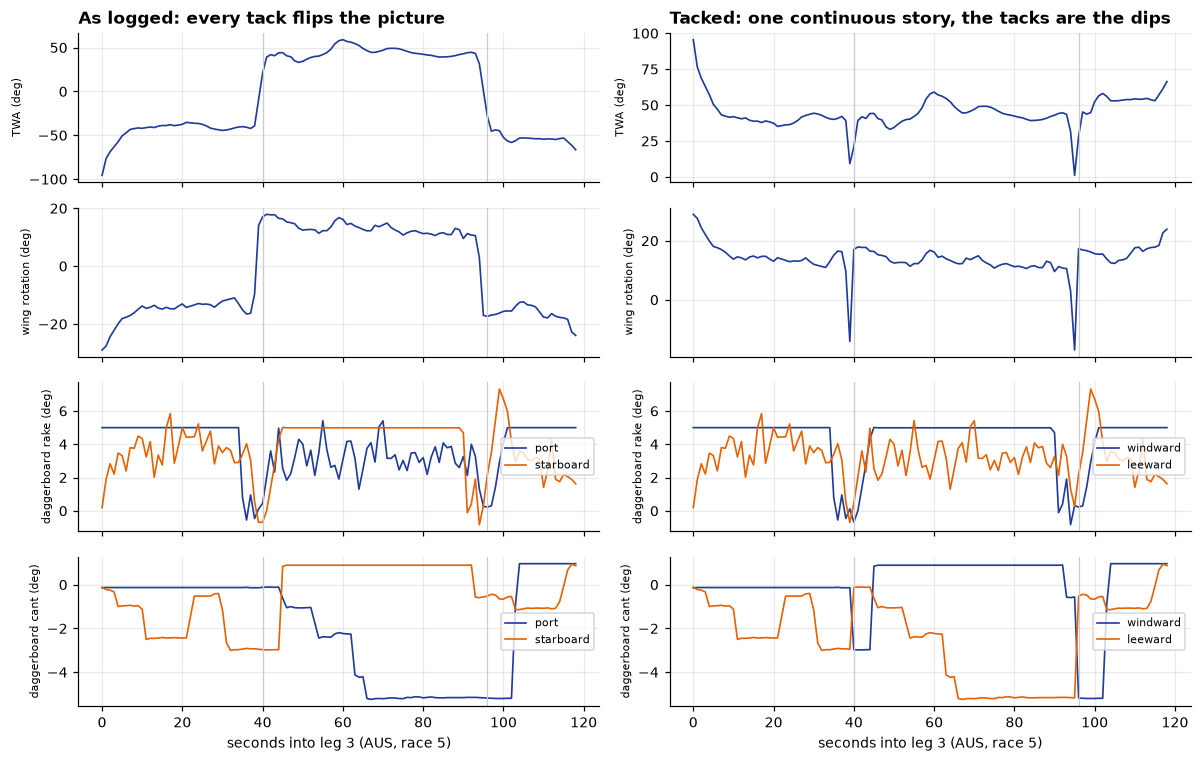

In [ ]:
leg3 = tk[(tk["BOAT"] == "AUS") & (tk["race"] == 25011905) & (tk["TRK_LEG_NUM_unk"] == 3)]
t = (leg3["DATETIME"] - leg3["DATETIME"].iloc[0]).dt.total_seconds()
panels = [("TWA (deg)", ["TWA_SGP_deg"], ["TWA_SGP_deg_tk"]),
          ("wing rotation (deg)", ["ANGLE_WING_ROT_deg"], ["ANGLE_WING_ROT_deg_tk"]),
          ("daggerboard rake (deg)", ["ANGLE_DB_RAKE_P_deg", "ANGLE_DB_RAKE_S_deg"], ["ANGLE_DB_RAKE_WW_deg", "ANGLE_DB_RAKE_LW_deg"]),
          ("daggerboard cant (deg)", ["ANGLE_DB_CANT_P_deg", "ANGLE_DB_CANT_S_deg"], ["ANGLE_DB_CANT_WW_deg", "ANGLE_DB_CANT_LW_deg"])]
names = {"P": "port", "S": "starboard", "WW": "windward", "LW": "leeward"}
fig, axes = plt.subplots(len(panels), 2, figsize=(11, 7), sharex=True)
for row, (label, raw_cols, tk_cols) in enumerate(panels):
    for col, cols in enumerate([raw_cols, tk_cols]):
        ax = axes[row, col]
        for i, c in enumerate(cols):
            side = [names[p] for p in c.split("_") if p in names]
            ax.plot(t, leg3[c], lw=1.1, color=["#1f3b99", "#e66101"][i], label=side[0] if side else None)
        for tt in t[leg3["tack"] != leg3["tack"].shift()].iloc[1:]:
            ax.axvline(tt, color="0.8", lw=0.8)
        ax.set_ylabel(label, fontsize=7)
        if len(cols) > 1:
            ax.legend(fontsize=7, loc="center right")
axes[0, 0].set_title("As logged: every tack flips the picture")
axes[0, 1].set_title("Tacked: one continuous story, the tacks are the dips")
axes[-1, 0].set_xlabel("seconds into leg 3 (AUS, race 5)")
axes[-1, 1].set_xlabel("seconds into leg 3 (AUS, race 5)")
plt.tight_layout()

A by-product: once the channels are tacked, a boat that is set up differently on the two tacks shows up directly
(USA's ride height row is the faulty sensor from 3.1, not a setup difference).

In [ ]:
asym = up.groupby(["BOAT", "tack"])[["TWA_SGP_deg_tk", "ANGLE_WING_ROT_deg_tk", "ANGLE_WING_TWIST_deg_tk", "HEEL_deg_tk", "LENGTH_RH_LW_mm", "BOAT_SPEED_km_h_1"]].median().unstack("tack")
diff = (asym.xs("port", axis=1, level="tack") - asym.xs("stbd", axis=1, level="tack")).round(1)
diff.columns = ["TWA", "wing rotation", "wing twist", "heel", "leeward ride height (mm)", "boat speed (km/h)"]
print("Upwind, port tack minus starboard tack (tacked channels)")
diff.T

Upwind, port tack minus starboard tack (tacked channels)


BOAT,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
TWA,-3.0,7.8,0.2,3.6,-4.9,5.4,0.4,3.0,-3.9,0.4
wing rotation,-1.5,1.7,0.2,1.2,-1.2,2.0,-0.6,-2.6,0.4,0.5
wing twist,-2.0,2.6,-1.6,0.6,2.5,0.2,1.7,2.3,-0.4,5.0
heel,1.2,-0.8,0.8,0.5,-0.4,0.0,1.3,0.0,0.0,0.8
leeward ride height (mm),14.1,-123.6,0.3,-22.8,-39.4,-48.9,41.3,8.7,-51.3,-1614.7
boat speed (km/h),-2.0,2.3,-0.0,-1.0,-0.9,5.1,3.5,-0.3,0.3,-1.2


## Question 7 — what makes a good tack

**Data.** The manoeuvre summary has 196 tacks. Kept: the 163 that are real upwind tacks (entry TWA below 65°, exit below 75°); the other 33 start or end on a reach (mark roundings and pre-start turns).
Of the 163, 107 are race tacks and 56 are pre-start tacks. The summary has no column description, so two things were read from the numbers:
every row covers a fixed 40 s window (`theoretical_distance` is exactly `theoretical_vmg` × 40 s), and the `flying` flag is 1 when the lowest ride height in the turn stays above 400 mm.

**Target.** `loss_vs_targ_vmg`: metres of upwind progress lost in those 40 s compared with sailing straight at the target VMG (it equals `theoretical_targ_distance − vmg_distance` in every row). It is in metres, it is already normalised for wind speed, and 0 means a free tack.

**First look: there are two kinds of tack.**

,n,loss_m,min_speed,exit_speed
foiling,,,,
came down,98,61.6,28.0,41.2
stayed on the foils,65,-6.7,39.3,51.8


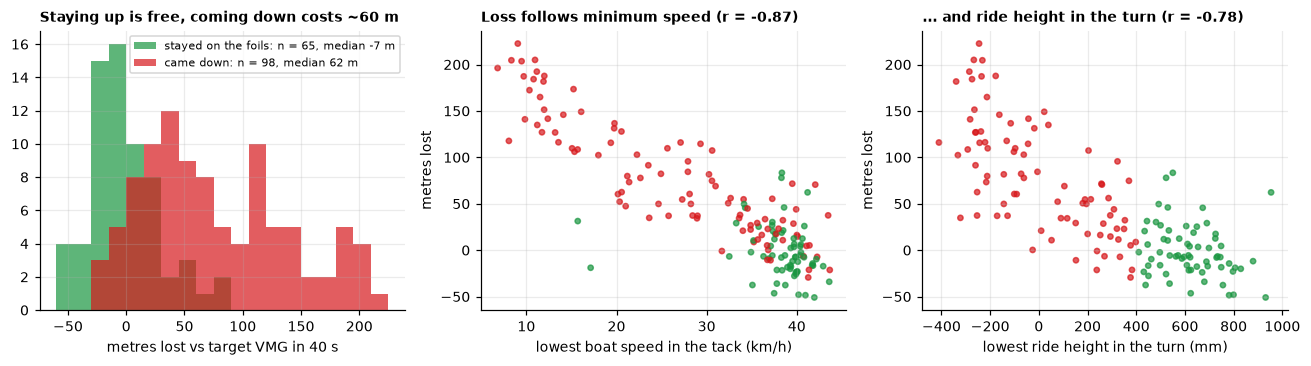

In [ ]:
tacks = man[(man["type"] == "tack") & (man["entry_twa"] < 65) & (man["exit_twa"] < 75)].copy()
for c in ("drop_time", "unstow_time"):
    tacks[c] = tacks[c + "_P"].fillna(tacks[c + "_S"])           # the board that was dropped
tacks["prestart"] = (tacks["leg"] == 0).astype(int)
tacks["foiling"] = tacks["flying"].map({1: "stayed on the foils", 0: "came down"})
y = tacks["loss_vs_targ_vmg"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ax = axes[0]
bins = np.arange(-60, 240, 15)
for label, colour in [("stayed on the foils", "#1a9641"), ("came down", "#d7191c")]:
    part = y[tacks["foiling"] == label]
    ax.hist(part, bins=bins, alpha=0.7, color=colour, label=f"{label}: n = {len(part)}, median {part.median():.0f} m")
ax.set_xlabel("metres lost vs target VMG in 40 s")
ax.set_title("Staying up is free, coming down costs ~60 m", fontsize=9)
ax.legend(fontsize=7)
for ax, col, label in [(axes[1], "min_bsp", "lowest boat speed in the tack (km/h)"), (axes[2], "turn_min_rh", "lowest ride height in the turn (mm)")]:
    ax.scatter(tacks[col], y, c=tacks["flying"].map({1: "#1a9641", 0: "#d7191c"}), s=12, alpha=0.7)
    ax.set_xlabel(label)
    ax.set_ylabel("metres lost")
axes[1].set_title(f"Loss follows minimum speed (r = {y.corr(tacks['min_bsp']):.2f})", fontsize=9)
axes[2].set_title(f"... and ride height in the turn (r = {y.corr(tacks['turn_min_rh']):.2f})", fontsize=9)
plt.tight_layout()
tacks.groupby("foiling").agg(n=("flying", "size"), loss_m=("loss_vs_targ_vmg", "median"), min_speed=("min_bsp", "median"), exit_speed=("exit_bsp", "median")).round(1)

So "optimising a tack for VMG" in this wind is mostly "do not come off the foils" (of the tacks that came down, about half reached a ride height of zero or less). The model has to explain *what the crew does* that leads there, so it only gets features the crew controls
**before and during** the turn. Minimum speed, exit speed, exit trim and the foiling flag are outcomes and are left out.

**Model.** With 163 rows, a regularised linear model on standardised features is the right size: the coefficients are directly readable (metres per standard deviation)
and there is not enough data to trust anything more flexible. Honest scoring: 5-fold cross-validation **grouped by boat**, so a tack is always predicted by a model that has never seen that team.

In [ ]:
FEATURES = {
    "entry_bsp": "entry boat speed",
    "entry_twa": "entry TWA",
    "entry_rh": "entry ride height",
    "entry_heel": "entry heel",
    "entry_pitch": "entry pitch (bow up +)",
    "max_yaw_rate": "peak turn rate",
    "turning_time": "turning time",
    "max_rudder_angle": "peak rudder angle",
    "drop_time": "new board drop time",
    "drop_to_wind_axis": "board drop to head-to-wind",
    "two_DB_time": "time on two boards",
    "t_to_lock": "time to lock",
    "heel_at_drop": "heel at board drop",
    "pitch_at_drop": "pitch at board drop",
    "winward_rh_at_drop": "windward ride height at drop",
    "entry_jib_sheet_pct": "entry jib sheet",
    "tws": "wind speed",
    "prestart": "pre-start tack",
}
X = tacks[list(FEATURES)]
groups = tacks["BOAT"]


def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 25)))


cv = GroupKFold(5)
pred = cross_val_predict(ridge(), X, y, groups=groups, cv=cv)
p_fly = cross_val_predict(make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)), X, tacks["flying"], groups=groups, cv=cv, method="predict_proba")[:, 1]
print(f"metres lost, unseen team : R2 = {r2_score(y, pred):.2f}, mean abs error = {mean_absolute_error(y, pred):.0f} m (spread of the target: {y.std():.0f} m)")
print(f"stays on the foils, unseen team: AUC = {roc_auc_score(tacks['flying'], p_fly):.2f}")

metres lost, unseen team : R2 = 0.78, mean abs error = 23 m (spread of the target: 65 m)
stays on the foils, unseen team: AUC = 0.84


,median,lo,hi
peak turn rate,-23.1,-28.5,-16.6
entry boat speed,-21.9,-31.0,-14.0
entry pitch (bow up +),-11.1,-18.7,-3.0
wind speed,-7.9,-12.2,-3.3
windward ride height at drop,-6.7,-11.5,-1.8
heel at board drop,4.4,0.5,9.7
turning time,4.5,2.0,7.3
pitch at board drop,7.9,2.3,14.5
entry TWA,10.3,7.0,13.8
peak rudder angle,11.2,6.6,14.4


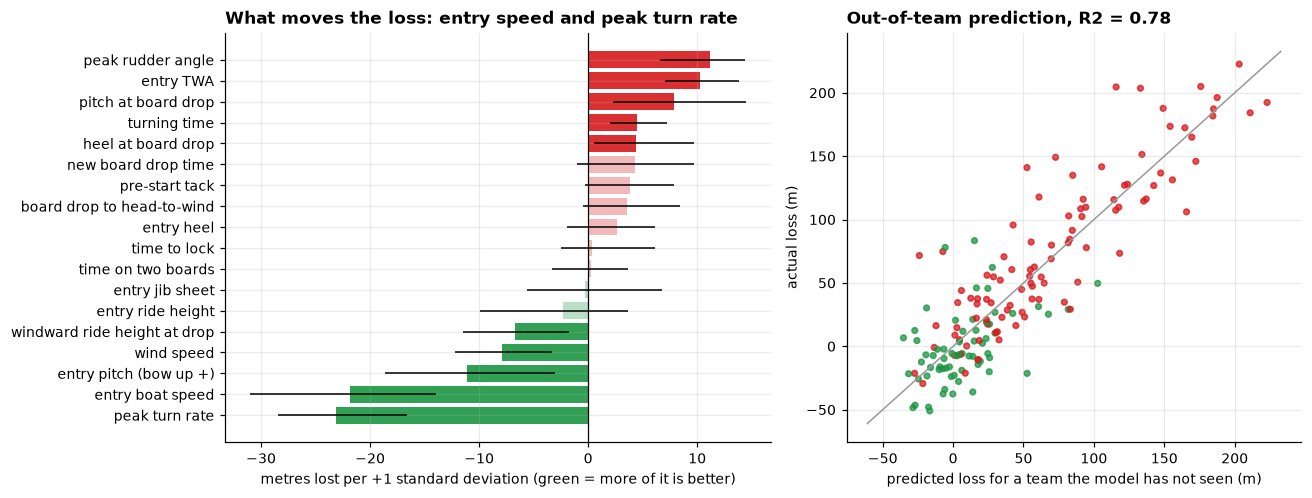

In [ ]:
rng = np.random.default_rng(0)
boats = groups.unique()
coefs = []
for _ in range(300):                                   # bootstrap whole teams, not single tacks
    pick = rng.choice(boats, size=len(boats), replace=True)
    idx = np.concatenate([np.flatnonzero(groups.to_numpy() == b) for b in pick])
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 25))).fit(X.iloc[idx], y.iloc[idx])
    coefs.append(model[-1].coef_)
coefs = pd.DataFrame(coefs, columns=[FEATURES[c] for c in FEATURES])
summary = pd.DataFrame({"median": coefs.median(), "lo": coefs.quantile(0.05), "hi": coefs.quantile(0.95)}).sort_values("median")
solid = (summary["lo"] > 0) | (summary["hi"] < 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ypos = np.arange(len(summary))
colours = np.where(summary["median"] < 0, "#1a9641", "#d7191c")
for keep, alpha in [(solid.to_numpy(), 0.9), (~solid.to_numpy(), 0.3)]:
    ax.barh(ypos[keep], summary["median"].to_numpy()[keep], color=colours[keep], alpha=alpha)
ax.hlines(ypos, summary["lo"], summary["hi"], color="k", lw=1)
ax.set_yticks(ypos, summary.index)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("metres lost per +1 standard deviation (green = more of it is better)")
ax.set_title("What moves the loss: entry speed and peak turn rate")
ax = axes[1]
ax.scatter(pred, y, c=tacks["flying"].map({1: "#1a9641", 0: "#d7191c"}), s=14, alpha=0.75)
lim = [y.min() - 10, y.max() + 10]
ax.plot(lim, lim, color="0.6", lw=1)
ax.set_xlabel("predicted loss for a team the model has not seen (m)")
ax.set_ylabel("actual loss (m)")
ax.set_title(f"Out-of-team prediction, R2 = {r2_score(y, pred):.2f}")
plt.tight_layout()
summary[solid].round(1)

Bars are the bootstrap median with a 90 % interval, resampling whole teams; faded bars have an interval that crosses zero.

**The same thing in sailors' units** — the tacks split into thirds on the two strongest levers and on entry ride height:

In [ ]:
def thirds(col, label, fmt):
    q = pd.qcut(tacks[col], 3)
    out = tacks.groupby(q, observed=True).agg(tacks=("flying", "size"), stayed_flying=("flying", "mean"), loss_m=("loss_vs_targ_vmg", "median"))
    out.index = [f"{label} {fmt.format(i.left)} to {fmt.format(i.right)}" for i in out.index]
    return out


levers = pd.concat([thirds("entry_bsp", "entry speed (km/h)", "{:.0f}"), thirds("max_yaw_rate", "peak turn rate (deg/s)", "{:.0f}"), thirds("entry_rh", "entry ride height (mm)", "{:.0f}")])
levers["stayed_flying"] = (100 * levers["stayed_flying"]).round(0).astype(int).astype(str) + " %"
levers.round(0)

,tacks,stayed_flying,loss_m
entry speed (km/h) 31 to 52,55,20 %,106.0
entry speed (km/h) 52 to 58,54,37 %,22.0
entry speed (km/h) 58 to 73,54,63 %,4.0
peak turn rate (deg/s) 8 to 25,55,7 %,110.0
peak turn rate (deg/s) 25 to 31,54,56 %,12.0
peak turn rate (deg/s) 31 to 41,54,57 %,5.0
entry ride height (mm) 53 to 879,52,21 %,103.0
entry ride height (mm) 879 to 995,51,55 %,9.0
entry ride height (mm) 995 to 1210,52,50 %,9.0


In [ ]:
team = tacks.groupby("BOAT").agg(tacks=("flying", "size"), stayed_flying=("flying", "mean"), loss_m=("loss_vs_targ_vmg", "median"), entry_speed=("entry_bsp", "median"),
                                 turn_rate=("max_yaw_rate", "median"), entry_ride_height=("entry_rh", "median")).sort_values("loss_m")
team["stayed_flying"] = (100 * team["stayed_flying"]).round(0)
team.round(1)

,tacks,stayed_flying,loss_m,entry_speed,turn_rate,entry_ride_height
BOAT,,,,,,
ESP,17,53.0,-2.1,58.5,29.6,957.3
AUS,19,58.0,6.7,56.8,29.7,984.6
DEN,18,44.0,10.0,57.4,33.3,905.4
GER,13,46.0,17.5,57.1,34.7,898.6
SUI,16,31.0,27.3,55.4,26.8,1002.2
NZL,19,42.0,30.3,54.7,30.9,862.2
BRA,13,23.0,37.5,55.6,25.0,970.1
USA,14,0.0,39.2,51.8,29.8,879.2
ITA,16,44.0,46.3,53.0,26.9,958.4


**Conclusions**

* The loss in a tack is decided by whether the boat stays on its foils: a median of −7 m when it does, 62 m when it does not. Only 4 in 10 tacks stayed up in this breeze (65 of 163).
* Two things the crew controls carry most of it, on teams the model never saw (R² 0.78, mean error 23 m): **entry speed** and **peak turn rate**, each worth about 22 m per standard deviation.
  Tacks entered below 52 km/h stay up 20 % of the time and lose 106 m; above 58 km/h it is 63 % and 4 m. Tacks with a peak turn rate below 25°/s stay up 7 % of the time and lose 110 m;
  above 25°/s it is 56 % and 5–12 m, with nothing more to gain above 31°/s. Slow turns are the expensive ones.
* Smaller but clear (the interval excludes zero): a flatter entry (the boats sail about 2° bow down; less of it is better), a narrow entry angle and more wind help;
  a large peak rudder angle, a long turning time, and a low windward hull or a less bow-down attitude at the moment the new board goes down cost metres.
* **Entry ride height** looks strong on its own (tacks entered below 880 mm stay up 21 % of the time, against 50–55 % above) but adds nothing once speed and turn rate are in the model.
  Board timing (drop time, time on two boards, time to lock) and the jib sheet show no effect that survives resampling the teams.
* Pre-start tacks lose far more than race tacks (median 97 m against 15 m; 1 in 5 stays up against 1 in 2), but they are entered slower, and with the entry numbers in the model the pre-start flag adds nothing clear.

**Caveats.** 163 tacks from one afternoon in 32–44 km/h: this is a description of that day, not a law. A third of them are pre-start tacks, where losing as little as possible is not always the aim.
Entry speed and entry ride height are correlated (r = 0.71) and both go with the turn rate (r ≈ 0.45), so the split between them is soft; their combined effect is not.
The features are observational: the model says which tacks were good, a team would still have to test whether forcing a faster turn helps. No more flexible model was tried.

## Question 8 — what made a team win or underperform

The finish gap to the winner is split exactly: how much later the boat crossed the start line, plus how much longer it took on each leg.
Each leg difference is then split into **sailed further** and **sailed slower** (time = distance / speed, so the two parts add up exactly).

In [ ]:
results, gaps, splits, starts, summaries = {}, {}, {}, {}, {}
for rid in RACES:
    times = race.leg_times(metrics[rid], courses[rid])
    gaps[rid] = race.gap_to_winner(times)
    summaries[rid] = race.leg_summary(metrics[rid], courses[rid])
    splits[rid] = race.distance_speed_split(summaries[rid], gaps[rid].index[0])
    starts[rid] = race.start_table(metrics[rid], courses[rid])
    results[rid] = gaps[rid]["total"]
order = pd.DataFrame({rid: pd.Series(range(1, len(results[rid]) + 1), index=results[rid].index) for rid in RACES})
board = pd.concat({"finish position": order, "seconds behind the winner": pd.DataFrame(results)}, axis=1)
board = board.reindex(order[RACES[:3]].sum(axis=1, skipna=False).sort_values().index)
board.round(0)

finish position                            seconds behind the winner                           
            25011905 25011906 25011907 25011908                  25011905 25011906 25011907 25011908
BOAT                                                                                                
DEN                8        1      1.0      NaN                      58.0      0.0      0.0      NaN
ESP                5        3      3.0      2.0                      36.0     11.0     41.0     23.0
GBR                2        4      6.0      3.0                      10.0     23.0     64.0     36.0
NZL                4        6      2.0      NaN                      34.0     35.0     32.0      NaN
GER                6        7      5.0      NaN                      43.0     40.0     57.0      NaN
BRA                7        5      7.0      NaN                      53.0     29.0     84.0      NaN
ITA                3        9      8.0      NaN                      28.0     50.0     88.0      NaN
SUI               10       10      4.0      NaN                      98.0     60.0     49.0      NaN
USA                9        8      9.0      NaN                      76.0     43.0     90.0      NaN
AUS                1        2      NaN      1.0                       0.0     10.0      NaN      0.0

Australia did not finish race 7 (its log stops at the first windward gate, four minutes after the start) and Canada never started.

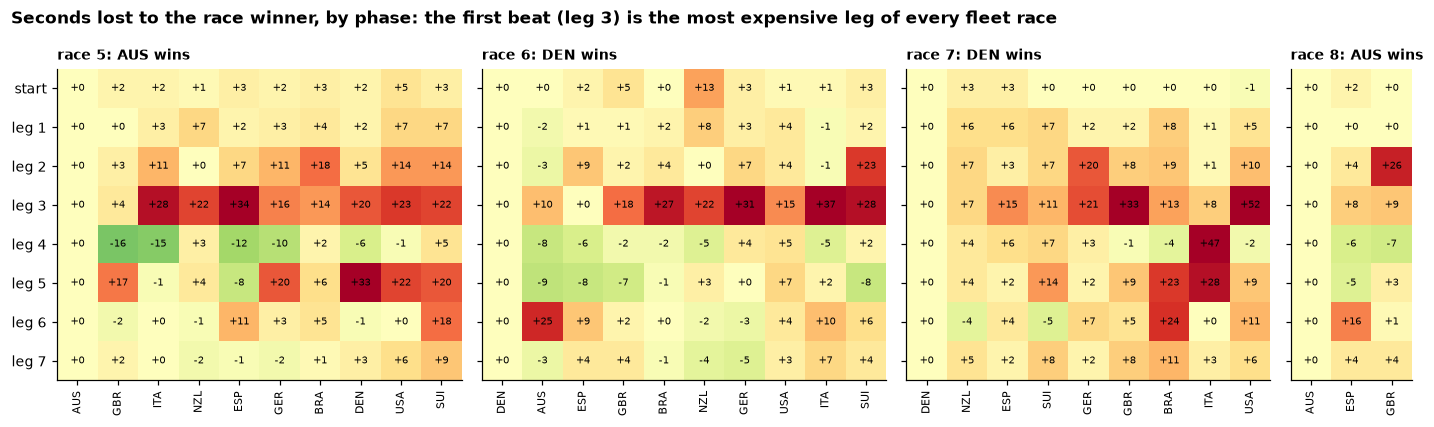

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.9), gridspec_kw={"width_ratios": [10, 10, 9, 3]})
for ax, rid in zip(axes, RACES):
    g = gaps[rid].drop(columns="total")
    im = ax.imshow(g.to_numpy().T, cmap="RdYlGn_r", vmin=-30, vmax=30, aspect="auto")
    ax.set_xticks(range(len(g)), g.index, rotation=90, fontsize=7)
    ax.set_yticks(range(g.shape[1]), g.columns if ax is axes[0] else [""] * g.shape[1])
    for (i, j), v in np.ndenumerate(g.to_numpy()):
        ax.text(i, j, f"{v:+.0f}", ha="center", va="center", fontsize=6.5)
    ax.set_title(f"race {rid % 100}: {g.index[0]} wins", fontsize=9)
    ax.grid(False)
fig.suptitle("Seconds lost to the race winner, by phase: the first beat (leg 3) is the most expensive leg of every fleet race", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()

In [ ]:
phase = pd.concat({rid: g.drop(columns="total").iloc[1:] for rid, g in gaps.items()})
share = phase.clip(lower=0).sum() / phase.clip(lower=0).sum().sum()
how = pd.concat({rid: s.groupby("BOAT")[["further_s", "slower_s"]].sum().reindex(gaps[rid].index[1:]) for rid, s in splits.items()})
off = pd.concat({rid: s["off_foil_s"].drop("USA", level="BOAT", errors="ignore").groupby("BOAT").sum() for rid, s in summaries.items()})
both = pd.concat([how.drop("USA", level=1, errors="ignore").sum(axis=1).rename("gap"), off.rename("off_foil")], axis=1).dropna()
print("Share of all time lost to winners, by phase:", ", ".join(f"{k} {v:.0%}" for k, v in share.items()))
print(f"Lost by sailing further: {how['further_s'].sum():.0f} s, by sailing slower: {how['slower_s'].sum():.0f} s  (all non-winning finishers, all races)")
print(f"Correlation between seconds off the foils and seconds lost on the legs: {both['gap'].corr(both['off_foil']):.2f}  (USA left out: ride height sensor)")

Share of all time lost to winners, by phase: start 4%, leg 1 6%, leg 2 15%, leg 3 37%, leg 4 6%, leg 5 15%, leg 6 11%, leg 7 6%
Lost by sailing further: 366 s, by sailing slower: 872 s  (all non-winning finishers, all races)
Correlation between seconds off the foils and seconds lost on the legs: 0.53  (USA left out: ride height sensor)


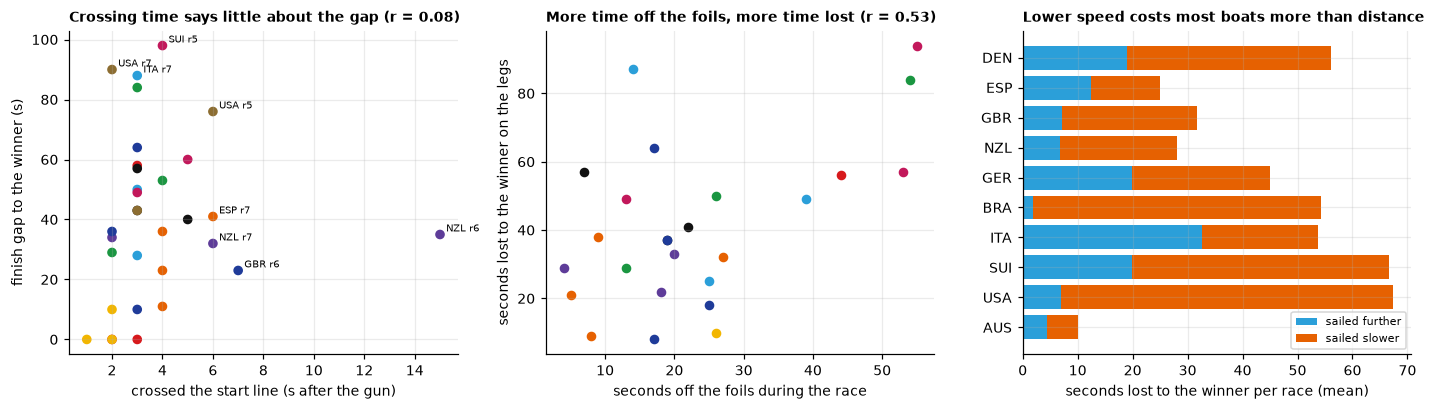

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
for rid in RACES:
    s = starts[rid].join(gaps[rid]["total"])
    ax.scatter(s["cross_s"], s["total"], c=[C[b] for b in s.index], s=28)
    for b, r in s.iterrows():
        if r["cross_s"] >= 6 or r["total"] > 85:
            ax.annotate(f"{b} r{rid % 100}", (r["cross_s"], r["total"]), fontsize=6.5, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("crossed the start line (s after the gun)")
ax.set_ylabel("finish gap to the winner (s)")
late = pd.concat({rid: starts[rid].join(gaps[rid]["total"]) for rid in RACES}).dropna()
ax.set_title(f"Crossing time says little about the gap (r = {late['cross_s'].corr(late['total']):.2f})", fontsize=9)

ax = axes[1]
for (rid, boat), r in both.iterrows():
    ax.scatter(r["off_foil"], r["gap"], color=C[boat], s=28)
ax.set_xlabel("seconds off the foils during the race")
ax.set_ylabel("seconds lost to the winner on the legs")
ax.set_title(f"More time off the foils, more time lost (r = {both['gap'].corr(both['off_foil']):.2f})", fontsize=9)

ax = axes[2]
h = how.groupby(level=1).mean().reindex(board.index).dropna()
ax.barh(h.index, h["further_s"], color="#2b9fd9", label="sailed further")
ax.barh(h.index, h["slower_s"], left=h["further_s"].clip(lower=0), color="#e66101", label="sailed slower")
ax.invert_yaxis()
ax.set_xlabel("seconds lost to the winner per race (mean)")
ax.set_title("Lower speed costs most boats more than distance", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()

In [ ]:
rid = 25011905
tbl = starts[rid].join(gaps[rid][["leg 1", "leg 2", "leg 3", "total"]]).join(summaries[rid]["off_foil_s"].groupby("BOAT").sum().rename("off_foil_s"))
tbl = tbl.join(man[(man["race"] == rid) & man["leg"].between(1, 7)].groupby("BOAT").size().rename("manoeuvres")).sort_values("total")
print("Race 5 in numbers")
tbl.round(0)

Race 5 in numbers


,at_gun_behind_line_m,at_gun_speed_kmh,cross_s,cross_speed_kmh,leg 1,leg 2,leg 3,total,off_foil_s,manoeuvres
BOAT,,,,,,,,,,
AUS,22.0,80.0,1.0,80.0,0.0,0.0,0.0,0.0,10.0,7
GBR,48.0,66.0,3.0,79.0,0.0,3.0,4.0,10.0,17.0,8
ITA,43.0,68.0,3.0,77.0,3.0,11.0,28.0,28.0,25.0,9
NZL,13.0,30.0,2.0,36.0,7.0,0.0,22.0,34.0,20.0,7
ESP,77.0,71.0,4.0,79.0,2.0,7.0,34.0,36.0,27.0,8
GER,39.0,49.0,3.0,64.0,3.0,11.0,16.0,43.0,22.0,8
BRA,48.0,49.0,4.0,63.0,4.0,18.0,14.0,53.0,26.0,7
DEN,38.0,61.0,3.0,70.0,2.0,5.0,20.0,58.0,44.0,9
USA,68.0,40.0,6.0,55.0,7.0,14.0,23.0,76.0,32.0,6


### What made the difference

**Winning**

* **Australia (1st in race 5, 1st in the final).** Won both from the start: across the line 1–2 s after the gun at 80 km/h, the fastest crossing of the fleet both times, first at mark 1 in race 5 and level with Britain there in the final.
  It then stayed on the foils: 10 s off them in race 5 and 1 s in the final. Britain was ahead for two minutes in race 5: it gained 16 s on the first run (leg 4), where Australia's first gybe came off the foils, and lost 17 s on the next beat.
* **Denmark (1st in races 6 and 7).** Both wins start with the fastest line crossing of the fleet (2–3 s after the gun at 74 and 65 km/h). In race 7 it led at mark 1 and took 7–52 s out of every other boat on the first beat.
  Race 6 was decided later: Australia was 12 s ahead of Denmark going into the last run and lost 25 s there with 22 s off the foils, while Denmark spent 5 s off the foils in the whole race.
  In race 5 the same boat spent 24 s off the foils on the second beat, lost 33 s on that leg and finished eighth.

**Underperforming**

* **The first beat costs the most.** Leg 3 alone accounts for 37 % of all time lost to winners, and it is the most expensive leg in each of the three fleet races. It is the first leg with tacks, and a tack that comes down costs about 60 m at once (Question 7).
* **A late start is paid once.** New Zealand crossed 15 s late at 23 km/h in race 6 and was 21 s behind at mark 1, which is 60 % of its 35 s at the finish. But in race 7 New Zealand and Spain crossed last (6 s) and finished second and third.
  Over all starts the crossing time says almost nothing about the finish gap (r = 0.08).
* **Time off the foils goes with most of the big losses** (r = 0.53 over all boats and races): Switzerland in race 5 (55 s off the foils, last), Australia's last run in race 6 (22 s, and the lead), Britain's leg 2 in the final (19 s off the foils, 26 s lost).
  It does not explain everything: Italy lost 47 s on leg 4 of race 7 with 3 s off the foils; it sailed almost 1.2 km further than Denmark in that race.
* **Sailing slower costs more than sailing further.** Across all finishers more than twice as much time went to lower speed (872 s) as to extra distance (366 s). Italy and Spain are the exceptions in race 5: they sailed 290 and 430 m further than Australia, and that accounts for most of their gap.

**Data caveats.** Finish times are taken from the last log sample where the log stops at the line. USA's starboard ride-height sensor is faulty, so its time off the foils rests on the other two sensors and is left out of the correlation.
With three fleet races these are descriptions of one afternoon, not rankings of the teams.